# 04 : Final comparison with the baseline (Step 3)
Owner: Enki. Every model registered in `src/models.py` is refitted on the full train set with its tuned
hyperparameters, then evaluated **once** on the test set. No choice is made from the test scores.

Protocol:
* ranking metrics: PR-AUC (main), ROC-AUC, recall when calling the top 20 % of clients (our business goal: 60 %);
* 95 % confidence intervals by bootstrap on the test rows (1,000 resamples);
* paired bootstrap against the logistic regression baseline: is the gain bigger than the noise?
* decision metrics (precision, recall, F1) at a threshold chosen on the **train** set (out-of-fold scores);
* robustness: same models trained on the oldest 80 % of calls and tested on the most recent 20 %.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path("..") / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

from common import *
from evaluation import *
from models import BUILDERS, get_model, load_best_params, score
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
set_seed()

df = load_clean()
train, test = random_split(df)
X_train, y_train = xy(train); X_test, y_test = xy(test)
# same test set as in notebook 02
assert (test.row_order.to_numpy() == pd.read_csv(RESULTS / "test_rows.csv").row_order.to_numpy()).all()
names = [n for n in BUILDERS if n == "dummy" or load_best_params(n) is not None]
print("models compared:", names)

models compared: ['dummy', 'logreg_baseline', 'decision_tree', 'knn', 'naive_bayes', 'linear_svc', 'random_forest', 'lightgbm']


## 1. Scores on the test set

In [2]:
cv = cv_folds()
scores, rows = {}, []
fitted, oofs, thresholds = {}, {}, {}
for n in names:
    m = get_model(n)
    # threshold chosen on out-of-fold scores of the train set, never on the test set
    oof = np.asarray([0.0])
    if n != "dummy":
        method = "predict_proba" if hasattr(m, "predict_proba") else "decision_function"
        oof = cross_val_predict(m, X_train, y_train, cv=cv, method=method, n_jobs=-1)
        oof = oof[:, 1] if oof.ndim == 2 else oof
    m.fit(X_train, y_train)
    fitted[n] = m
    sc = score(m, X_test); scores[n] = sc
    row = {"model": n, **ranking_metrics(y_test, sc)}
    lo, hi = bootstrap_ci(y_test, sc, average_precision_score); row["pr_auc_ci"] = f"[{lo:.3f}, {hi:.3f}]"
    lo, hi = bootstrap_ci(y_test, sc, recall_at_top); row["recall_top20_ci"] = f"[{lo:.3f}, {hi:.3f}]"
    if n != "dummy":
        t = best_f1_threshold(y_train, oof)
        oofs[n], thresholds[n] = oof, t
        row.update(threshold_metrics(y_test, sc, t))
    rows.append(row)
test_table = pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False)
test_table.to_csv(RESULTS / "test_comparison.csv")
test_table

,pr_auc,roc_auc,recall_top20,pr_auc_ci,recall_top20_ci,precision,recall,f1
model,,,,,,,,
random_forest,0.4978,0.8170,0.6713,"[0.461, 0.530]","[0.641, 0.698]",0.4788,0.5970,0.5314
lightgbm,0.4904,0.8136,0.6659,"[0.453, 0.523]","[0.637, 0.693]",0.4764,0.5970,0.5299
decision_tree,0.4719,0.8047,0.6400,"[0.434, 0.503]","[0.609, 0.668]",0.4610,0.5603,0.5058
logreg_baseline,0.4540,0.8004,0.6401,"[0.418, 0.488]","[0.612, 0.669]",0.4488,0.5862,0.5084
linear_svc,0.4490,0.7968,0.6433,"[0.412, 0.484]","[0.611, 0.670]",0.4493,0.5819,0.5070
knn,0.4480,0.7996,0.6519,"[0.413, 0.481]","[0.620, 0.681]",0.4427,0.5916,0.5065
naive_bayes,0.3987,0.7819,0.6121,"[0.365, 0.432]","[0.581, 0.638]",0.4188,0.4332,0.4258
dummy,0.1127,0.5000,0.2001,"[0.105, 0.120]","[0.200, 0.200]",NaN,NaN,NaN


* Every model is far above the dummy (PR-AUC 0.113, which is just the share of yes). The logistic regression
  baseline gets **PR-AUC 0.454 [0.418, 0.488]** and ROC-AUC 0.800, close to the AUC ≈ 0.8 of Moro et al.
* **Business goal reached by the baseline:** by calling the top 20 % of the list, the bank reaches 64.0 % of the
  subscribers [61.2 %, 66.9 %], above the 60 % we fixed in step 1, and 3.2 times better than random calls.
* **The step 3 models are the best on the test set:** random forest **0.498 [0.461, 0.530]** (ROC-AUC 0.817,
  67.1 % of the subscribers with 20 % of the calls) and LightGBM **0.490 [0.453, 0.523]** (ROC-AUC 0.814, 66.6 %).
  This is the same order as in cross-validation (notebook 03: 0.465 and 0.467 against 0.448 for the baseline), so
  for these two models the test set confirms what the folds said, unlike the decision tree.
* The confidence intervals still overlap (with 8,236 test rows and only 928 yes, the test PR-AUC is uncertain by
  about ±0.035), so the gains are tested properly with the paired bootstrap in section 2.
* At the threshold chosen on the train set (max F1), the baseline finds 59 % of the subscribers with a precision of
  45 %; the random forest finds 60 % with a precision of 48 % (F1 0.531 against 0.508).

### 1.1 Why the threshold is chosen on out-of-fold scores
For each model we compare the threshold chosen on out-of-fold (OOF) train scores with the one chosen on the
scores of the final model on its own training rows (in-sample), and the F1 each gives on the test set.
This is only a check of the protocol: the in-sample threshold is never used.

In [3]:
rows = []
for n, t_oof in thresholds.items():
    s_in = score(fitted[n], X_train)
    t_in = best_f1_threshold(y_train, s_in)
    rows.append({"model": n,
                 "train_pr_auc_in_sample": average_precision_score(y_train, s_in),
                 "train_pr_auc_oof": average_precision_score(y_train, oofs[n]),
                 "threshold_oof": t_oof, "threshold_in_sample": t_in,
                 "test_f1_oof": threshold_metrics(y_test, scores[n], t_oof)["f1"],
                 "test_f1_in_sample": threshold_metrics(y_test, scores[n], t_in)["f1"]})
thr_table = pd.DataFrame(rows).set_index("model")
thr_table.to_csv(RESULTS / "threshold_oof_vs_in_sample.csv")
thr_table

,train_pr_auc_in_sample,train_pr_auc_oof,threshold_oof,threshold_in_sample,test_f1_oof,test_f1_in_sample
model,,,,,,
logreg_baseline,0.4549,0.4478,0.2014,0.2144,0.5084,0.5068
decision_tree,0.4642,0.4421,0.7064,0.7401,0.5058,0.5058
knn,0.4424,0.4303,0.1709,0.1709,0.5065,0.5065
naive_bayes,0.3903,0.3892,0.7250,0.7237,0.4258,0.4256
linear_svc,0.4517,0.4453,-0.5870,-0.5868,0.5070,0.5063
random_forest,0.5621,0.4627,0.6019,0.7295,0.5314,0.5110
lightgbm,0.4988,0.4648,0.2079,0.2527,0.5299,0.5267


* For the logistic regression the two thresholds are almost the same (0.201 OOF, 0.214 in-sample) and the test F1
  does not change (0.508 OOF, 0.507 in-sample): a linear model with C = 0.1 cannot learn its training rows by heart.
* **For the random forest the difference is large:** its PR-AUC on its own training rows is 0.562, against 0.463 on
  rows it has not seen (OOF). Its scores on the train set are too confident, so the in-sample threshold is too
  high (0.730 against 0.602) and the test F1 drops from 0.531 to 0.511. LightGBM is in between (threshold 0.208 OOF
  against 0.253 in-sample, test F1 0.530 against 0.527), which matches its smaller train/CV gap in notebook 03.
* So the OOF threshold is needed as soon as the model is flexible. This is why it is computed for every model.
* The threshold of the random forest (0.60) is much higher than the others because it uses
  `class_weight="balanced_subsample"`: all its probabilities are pushed up, so they cannot be read as real
  probabilities. The ranking (PR-AUC) is not affected, and the threshold chosen on OOF scores corrects the shift.

## 2. Is the gain over the baseline real? (paired bootstrap)

In [4]:
base = scores["logreg_baseline"]
rows = []
for n in names:
    if n in ("logreg_baseline", "dummy"):
        continue
    for metric_name, metric in [("pr_auc", average_precision_score), ("recall_top20", recall_at_top)]:
        r = paired_bootstrap_diff(y_test, scores[n], base, metric)
        rows.append({"model": n, "metric": metric_name, **r})
paired = pd.DataFrame(rows)
paired.to_csv(RESULTS / "paired_vs_baseline.csv", index=False)
paired

,model,metric,diff,ci_low,ci_high,p_not_better
0,decision_tree,pr_auc,0.0172,0.0009,0.0335,0.015
1,decision_tree,recall_top20,-0.0021,-0.0185,0.0133,0.595
2,knn,pr_auc,-0.0067,-0.0217,0.0081,0.794
3,knn,recall_top20,0.0094,-0.0047,0.0227,0.086
4,naive_bayes,pr_auc,-0.0559,-0.0735,-0.0376,1.000
5,naive_bayes,recall_top20,-0.0301,-0.0507,-0.0110,0.999
6,linear_svc,pr_auc,-0.0050,-0.0108,0.0010,0.947
7,linear_svc,recall_top20,0.0018,-0.0065,0.0095,0.365
8,random_forest,pr_auc,0.0433,0.0285,0.0567,0.000
9,random_forest,recall_top20,0.0284,0.0125,0.0440,0.000


In [5]:
# the two step 3 models against each other (same resampled rows)
if "random_forest" in scores and "lightgbm" in scores:
    rows = [{"metric": k, **paired_bootstrap_diff(y_test, scores["random_forest"], scores["lightgbm"], f)}
            for k, f in [("pr_auc", average_precision_score), ("recall_top20", recall_at_top)]]
    rf_vs_lgbm = pd.DataFrame(rows)
    rf_vs_lgbm.to_csv(RESULTS / "paired_rf_vs_lightgbm.csv", index=False)
    display(rf_vs_lgbm)

,metric,diff,ci_low,ci_high,p_not_better
0,pr_auc,0.0073,-0.0026,0.0167,0.073
1,recall_top20,0.0030,-0.0078,0.0139,0.341


* **Random forest and LightGBM beat the baseline in a reliable way:** PR-AUC +0.043 [+0.029, +0.057] and +0.036
  [+0.024, +0.047]; the random forest is never below the baseline in the 1,000 resamples. The gain is also there on
  the business metric: +2.8 points [+1.3, +4.4] and +2.5 points [+1.2, +3.9] of subscribers reached with 20 % of
  the calls (about 67 % instead of 64 %). Three reasons to trust it: it is significant here, it goes in the same
  direction as cross-validation, and it was expected (ensembles of trees capture interactions that a linear model
  cannot).
* **We cannot separate the two:** random forest minus LightGBM = +0.007 [-0.003, +0.017] in PR-AUC and +0.3 point
  [-0.8, +1.4] in recall at 20 %. In cross-validation the order is reversed (LightGBM 0.467, random forest 0.465).
  If one model has to be kept, the choice must not come from the test set: we would take **LightGBM**, because it
  is equal in CV, overfits less (train/CV gap 0.04 against 0.11) and is about 8 times faster to fit.
* The decision tree is still not a reliable gain (better on test PR-AUC, worse in CV, no gain on recall at 20 %).
  KNN and linear SVM are equal to the baseline, Naive Bayes is significantly worse.

## 3. Precision-recall and gain curves

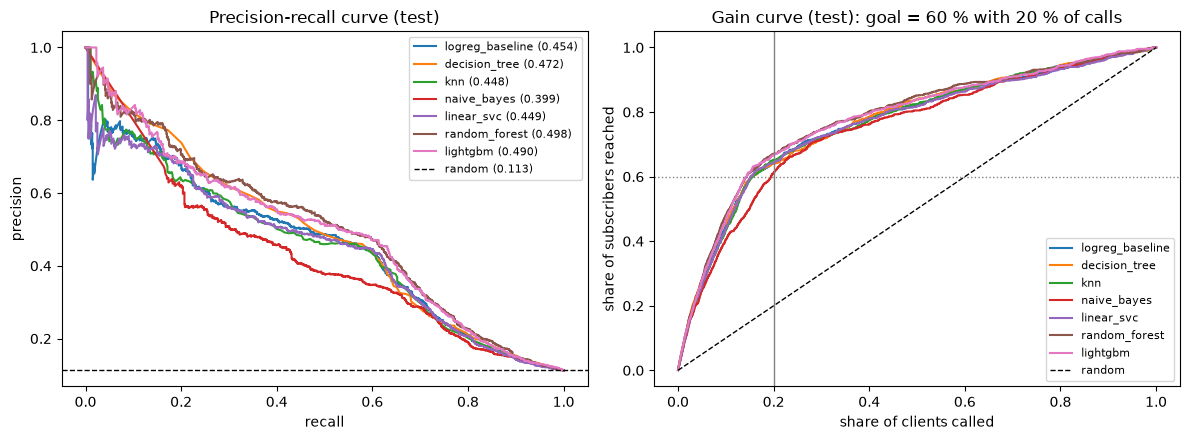

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for n in names:
    if n == "dummy":
        continue
    p, r, _ = precision_recall_curve(y_test, scores[n])
    axes[0].plot(r, p, label=f"{n} ({average_precision_score(y_test, scores[n]):.3f})")
    called, reached = gain_curve(y_test, scores[n])
    axes[1].plot(called, reached, label=n)
axes[0].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"random ({y_test.mean():.3f})")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-recall curve (test)")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[1].axvline(0.2, color="grey", lw=1); axes[1].axhline(0.6, color="grey", lw=1, ls=":")
axes[1].set_xlabel("share of clients called"); axes[1].set_ylabel("share of subscribers reached")
axes[1].set_title("Gain curve (test): goal = 60 % with 20 % of calls")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "test_pr_gain_curves.png", dpi=150); plt.show()

## 4. Robustness: train on the past, test on the most recent calls

In [7]:
old, recent = temporal_split(df)
X_old, y_old = xy(old); X_rec, y_rec = xy(recent)
print("share of yes  old 80 %%: %.3f   recent 20 %%: %.3f" % (y_old.mean(), y_rec.mean()))
rows = []
for n in names:
    m = get_model(n).fit(X_old, y_old)
    sc = score(m, X_rec)
    r = ranking_metrics(y_rec, sc)
    r["pr_auc_over_prevalence"] = r["pr_auc"] / y_rec.mean()   # PR-AUC depends on the share of yes, this makes it comparable
    r["random_split_pr_auc_over_prevalence"] = test_table.loc[n, "pr_auc"] / y_test.mean()
    r["random_split_roc_auc"] = test_table.loc[n, "roc_auc"]
    if hasattr(m, "predict_proba"):
        r["mean_proba"] = sc.mean()
    rows.append({"model": n, **r})
temporal = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)
temporal.to_csv(RESULTS / "temporal_comparison.csv")
temporal

share of yes  old 80 %: 0.064   recent 20 %: 0.308


,pr_auc,roc_auc,recall_top20,pr_auc_over_prevalence,random_split_pr_auc_over_prevalence,random_split_roc_auc,mean_proba
model,,,,,,,
linear_svc,0.5232,0.7495,0.3860,1.6972,3.9851,0.7968,NaN
logreg_baseline,0.5427,0.7476,0.3868,1.7605,4.0289,0.8004,0.2239
naive_bayes,0.5393,0.7324,0.3946,1.7493,3.5381,0.7819,0.8488
knn,0.4975,0.6923,0.3849,1.6137,3.9764,0.7996,0.1375
random_forest,0.4758,0.6790,0.3427,1.5433,4.4179,0.8170,0.4489
lightgbm,0.4949,0.6757,0.3671,1.6052,4.3526,0.8136,0.0873
decision_tree,0.3400,0.5422,0.2335,1.1028,4.1883,0.8047,0.4217
dummy,0.3083,0.5000,0.2001,1.0000,1.0000,0.5000,0.0638


When we train on the past and test on the most recent calls, everything gets worse, and some models break:
* The share of yes goes from 6.4 % in the old data to 30.8 % in the recent data. The PR-AUC values cannot be
  compared directly, so we divide them by the share of yes (a rough correction only; the ROC-AUC, which does
  not depend on the share of yes, gives the same message): the baseline goes from 4.0 times better than random
  (random split) to only 1.76 times. Its ROC-AUC drops from 0.80 to 0.75.
* The recall in the top 20 % falls to about 0.39 (the best possible is 0.65 since there are now more yes than
  20 % of the calls).
* **The step 3 models lose their advantage and fall below the baseline:** ROC-AUC 0.817 → 0.679 for the random
  forest and 0.814 → 0.676 for LightGBM, against 0.800 → 0.748 for the logistic regression. Recall at 20 %:
  0.34 and 0.37 against 0.39. They are made of trees, so they have the same problem as the decision tree, only
  smaller: 99 % of the recent calls have a `euribor3m` lower than anything seen in training (0.63-1.30 against
  1.30-5.05), and a tree puts all of them in the leaf of the lowest value it has seen.
* **The decision tree collapses** (ROC-AUC 0.54, almost random): only 36 different scores for 8,236 calls. Linear
  models extend the trend and survive better (linear SVM and logistic regression 0.75).
* **The probabilities are wrong after the drift:** the baseline predicts on average 0.224 when the real share is
  0.308; LightGBM predicts 0.087, so it underestimates the success rate by a factor 3.5. (The mean of the random
  forest, 0.449, means nothing: its probabilities are pushed up by the balanced class weights.)

This is the main limitation of the project: the random split gives optimistic scores because the
economic variables tell the model *when* the call was made, and the most flexible models use this the most.

## 5. Conclusion
* The logistic regression baseline (C = 0.1, no class weight) reaches the goal of step 1: 64 % of the
  subscribers with 20 % of the calls on the test set, AUC 0.80 like the literature.
* The standard algorithms of AutoML v0.1 do not beat it in a significant way (paired bootstrap).
* **The tuned random forest and LightGBM of step 3 do:** PR-AUC about 0.49-0.50 against 0.454, and about 67 % of
  the subscribers reached with 20 % of the calls. The gain is significant on the test set and consistent with
  cross-validation. The two are equivalent; by CV, overfitting and fit time we would keep LightGBM.
* **But the gain does not survive the drift:** trained on the past and tested on the most recent calls, both fall
  below the logistic regression (ROC-AUC 0.68 against 0.75), because trees cannot extrapolate the economic
  variables. The choice depends on how the bank uses the model: retrained often on recent calls (economy within
  the range seen in training), LightGBM ranks better; used for a long time without retraining, the logistic
  regression is safer. In both cases the model must be retrained and its probabilities recalibrated regularly.
* The threshold must be chosen on out-of-fold scores: for the random forest, a threshold chosen on its own
  training rows would lose 0.02 of F1 on the test set.
* Still to add (step 3, part 2): the ensemble and the model outside the course. They are registered in
  `src/models.py` and this notebook is run again: the tables and figures update by themselves, but the comments
  above must be checked against the new numbers.